# Notebook 07 — Practice with route help: reinforcement learning for the route-guided car

Notebook 06 ended with a car that gets **route help** from a server reading a ceiling camera: the next points on the
shortest obstacle-free path, 9 numbers every half second. With the server's better obstacle map it succeeds in **94%**
of the 128 test rooms (the car with only its front camera: 75%).

**What still goes wrong:** 7 of its 8 failed drives are cars **stuck on something**, mostly in the rooms where a box is
in the way. The route says *where* to drive, but when the car clips a corner, it doesn't know how to back off. The
demonstrations never showed that: the scripted driver never touched anything.

Notebook 05 met the same problem without route help, and **practice by trial and error (PPO) fixed it**: stuck failures
went from 16 to 1. But success didn't rise there, because the freed car then lost the goal and had no route to find it
again. This car *has* a route. So the question is:

> **Does notebook 05's practice, done with the route help switched on, fix the remaining stuck cars and push
> success towards the perfect-route car's 99%?**

**The setup**

| Choice | What we use |
|---|---|
| Start from | notebook 06's real-route car with the better map (`car06_R_long_s0.pt`, 94%) |
| Help during practice | the **real** server, as in the tests: SmolVLM2 + learned map + colour + planner once per drive, marker tracking every half second |
| Algorithm, reward, settings | **exactly notebook 05's**: PPO with ReinFlow-style jitter; progress, success, time, crash and sight terms; 8 CPU simulators; the "practise the demos" lesson (now with the demos' real routes) |
| What learns | the action head, the jitter size and a new critic. The reader, the help layer and the server stay locked. |
| How long | at least 100 rounds; then on until the quick test hasn't improved for 30 rounds (at most 200) |

**What you will learn here**
1. How to put an outside helper (the server) into an RL loop without making practice unaffordable.
2. Why practice can teach what demonstrations can't (backing off), and what it can't (where to go).
3. How to judge an RL run that starts from an already good model, where the quick test sits near the top.
4. Reading the before/after comparison drive by drive.

**Time and hardware:** about 2.5 minutes per round on an RTX 4080 SUPER + 20-core CPU (a bit slower than notebook 05:
every simulator also draws and tracks the ceiling picture). 100 rounds ≈ 4 hours, 200 ≈ 8 hours. GPU memory: about
6 GB for training plus the server. If a finished run is in `runs/rl/car07_route_ppo_s0`, the notebook only draws its
charts (set `FORCE = True` in section 6 to train again).

## 1. Setup

Close other notebooks that hold a model (see notebook 05, section 1). `PYTORCH_CUDA_ALLOC_CONF` must be set before
torch is imported.

In [2]:
import os, sys, json, time, shutil, subprocess
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")  # must happen before torch is imported
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)
RUNS = PROJECT_ROOT / "runs"

PREP = RUNS / "datasets" / "route_follow_prep.json"                    # notebook 06 (the demos for the imitation lesson)
START_CHECKPOINT = RUNS / "checkpoints" / "car06_R_long_s0.pt"         # notebook 06, section 8.7
RUN_DIR = RUNS / "rl" / "car07_route_ppo_s0"
assert START_CHECKPOINT.exists(), "Run notebook 06 first (section 8.7 trains the starting car)."

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

from carsim import nb06
from carsim.device import describe
from carsim.ppo import plot_progress, plot_health
from carsim.route_ppo import RoutePPOConfig, RoutePPOTrainer
print(describe())
if shutil.which("nvidia-smi"):
    print(subprocess.run(["nvidia-smi", "--query-gpu=memory.used,memory.total", "--format=csv"], capture_output=True, text=True).stdout)

device = cuda: NVIDIA GeForce RTX 4080 SUPER, 15.6 GB | PyTorch 2.15.0+cu134 | Linux 7.2.14-arch1-1
memory.used [MiB], memory.total [MiB]
862 MiB, 16376 MiB



## 2. What is left to fix

The starting car's failures, from notebook 06's tests (same 128 rooms). "Stuck" = the failed drive spent more than 2 s
touching something. The rooms are split into thirds by how much detour the obstacles force (the shortest obstacle-free
route divided by the straight line to the goal).

In [2]:
START = [("front camera only", "F_s0", "help"), ("route car (start of this notebook)", "car06_R_long_s0", "help"),
         ("perfect route (upper limit)", "car06_Rstar_s0", "help")]
display(nb06.summary(START))
display(nb06.detour_thirds(START))

,success,goal hidden at start,box in the way,touched something,s per success,"s per success, hidden",failures,...stuck
car,,,,,,,,
front camera only,75%,69%,50%,52%,14.3,23.1,32,25
route car (start of this notebook),94%,92%,90%,22%,8.0,11.0,8,7
perfect route (upper limit),99%,100%,95%,4%,6.8,8.8,1,1


,least detour,middle,most detour
car,,,
front camera only,84% (5 stuck),76% (8 stuck),65% (12 stuck)
route car (start of this notebook),100% (0 stuck),93% (2 stuck),88% (5 stuck)
perfect route (upper limit),100% (0 stuck),100% (0 stuck),98% (1 stuck)


**Reading it.** In the rooms needing the least detour, the route car never fails. Its failures sit in the rooms needing
the most detour (88%, 5 stuck), where the perfect-route car still gets 98%. The difference between the two is the
route's small mistakes: the learned map draws an obstacle a little too thin, the route clips a corner, and the car
gets pinned. A car that has learned to **back off and follow the route again** would recover from most of these.

This is exactly the skill notebook 05's practice taught: its crash cost (−0.1 per 0.1 s touching something) made the
car learn to get off obstacles.

## 3. Route help during practice, without making practice unaffordable

In the tests, the server runs on every half-second decision. In practice that would be expensive: 2,048 decisions per
round, each with SmolVLM2 reading a 1024 px picture. But nothing in the room except the car moves. Obstacles and
objects stay put for a whole drive. So the server's work splits into two parts (`carsim/route_ppo.py`):

```
 at the start of every drive (once)                  every half second (cheap)
 ─────────────────────────────────                   ──────────────────────────
 the simulator sends its ceiling picture             the simulator draws the ceiling picture and
 SmolVLM2: which object is the goal, picture tokens  tracks the roof marker -> car x, y, heading (CPU)
 learned map: where the obstacles are                the trainer reads the next 3 route points off the
 colour: the goal's exact position                   drive's distance field from that pose
 planner: distance field (route length from every    -> 9 numbers -> the car's 8 help tokens
          spot of the room to the goal)
```

The plan is the same one the tests rebuild every half second (up to small flicker in the map from picture to picture),
so practice sees the help the tests will give. The planner's **distance field** is what makes this cheap: it already
holds the shortest route from *every* spot in the room, so wherever the car slides, the next points are read off it.

The "practise the demos" lesson needs help too: each demo frame gets the **real** route the server worked out for it
in notebook 06 (with help removed 20% of the time, as in the car's imitation training).

## 4. The score and the settings: notebook 05's, unchanged

| Part | Rule |
|---|---|
| progress | +1 per metre closer to the goal along the shortest obstacle-free path (−1 per metre farther) |
| success | +2.5 for arriving and stopping at the right object |
| time | −0.01 per 0.1 s step |
| crash | **−0.1 per step touching anything except the goal**: the part that teaches backing off |
| sight | +0.2 when the goal comes into view, −0.3 when it leaves the picture |

Notebook 05, section 2 explains each term and why none of them can be cheated. Practice rooms are harder than the test
on purpose: the goal starts hidden in 3 of 4 drives. All settings, with comments, are in `PPOConfig` (`carsim/ppo.py`);
`RoutePPOConfig` adds where the server and its map are:

In [3]:
cfg = RoutePPOConfig()
for k, v in vars(cfg).items():
    print(f"{k:24s} {v}")

n_envs                   8
decisions_per_round      256
practice_layout          {'p_goal_visible': 0.25, 'p_hard_distractor': 0.5}
exec_steps               5
denoise_steps            4
gamma                    0.995
gae_lambda               0.95
epochs                   2
minibatch                32
micro_batch              16
clip                     0.2
target_kl                0.05
actor_lr                 1e-06
critic_lr                0.0003
sigma_lr                 0.001
sigma_init               0.08
sigma_min                0.02
sigma_max                0.2
max_grad_norm            1.0
critic_warmup_rounds     5
bc_batch                 16
bc_mirror_p              0.0
bc_coef_start            1.0
bc_coef_end              0.1
bc_decay_rounds          100
eval_every               10
eval_episodes_per_env    4
eval_seed                999
seed                     0
full_precision           True
reward                   RewardConfig(progress=1.0, success=2.5, time=-0.01, crash=-0.1

## 5. When to stop

Notebook 05 ran 100 rounds. The "practise the demos" lesson fades from full weight to its final low weight over those
100 rounds, so PPO only gets its full freedom towards the end. Here we run **at least 100 rounds, then keep going
while the 32-room quick test keeps improving**: we stop once its score hasn't set a new best for 30 rounds (or at round
200). `best.pt` is always the round with the best quick-test score.

**A caution for this run:** the starting car already succeeds in ~94% of rooms, so the 32-room quick test often sits at
29–32 of 32. A single quick test can't show small gains (±15 points is ordinary luck on 32 drives). Watch the
**crash** line and the **score** instead, and trust only the full 128-room tests at the end.

## 6. Train

If `RUN_DIR` already holds a finished run, this cell only redraws its charts. Otherwise it trains here, with the graphs
redrawn after every round (stop any time with ■; run the cell again to continue from `latest.pt`). The same run can be
started outside the notebook: `python scripts/train_guided_ppo.py --route --init runs/checkpoints/car06_R_long_s0.pt
--run runs/rl/car07_route_ppo_s0 --rounds 200 --patience 30 --min_rounds 100`.

**How to read the graphs** (as in notebook 05, section 7)

| Graph | Healthy | Warning sign |
|---|---|---|
| **Success rate** | test dots stay high (they start near the top) | falling for many rounds in a row |
| **Score per drive** | rising | falling |
| **Drives with a crash** | **falling**: the main thing we hope to see | falling *together with* success → the "don't move" trap |
| **Critic accuracy** | 0.2–0.8 after the warm-up | near 0 or negative |
| **Size of each update** | KL below 0.05, clipped below ~0.3 | study done very low every round |
| **Jitter σ** | slowly shrinks or stays | collapses to 0.02 early |

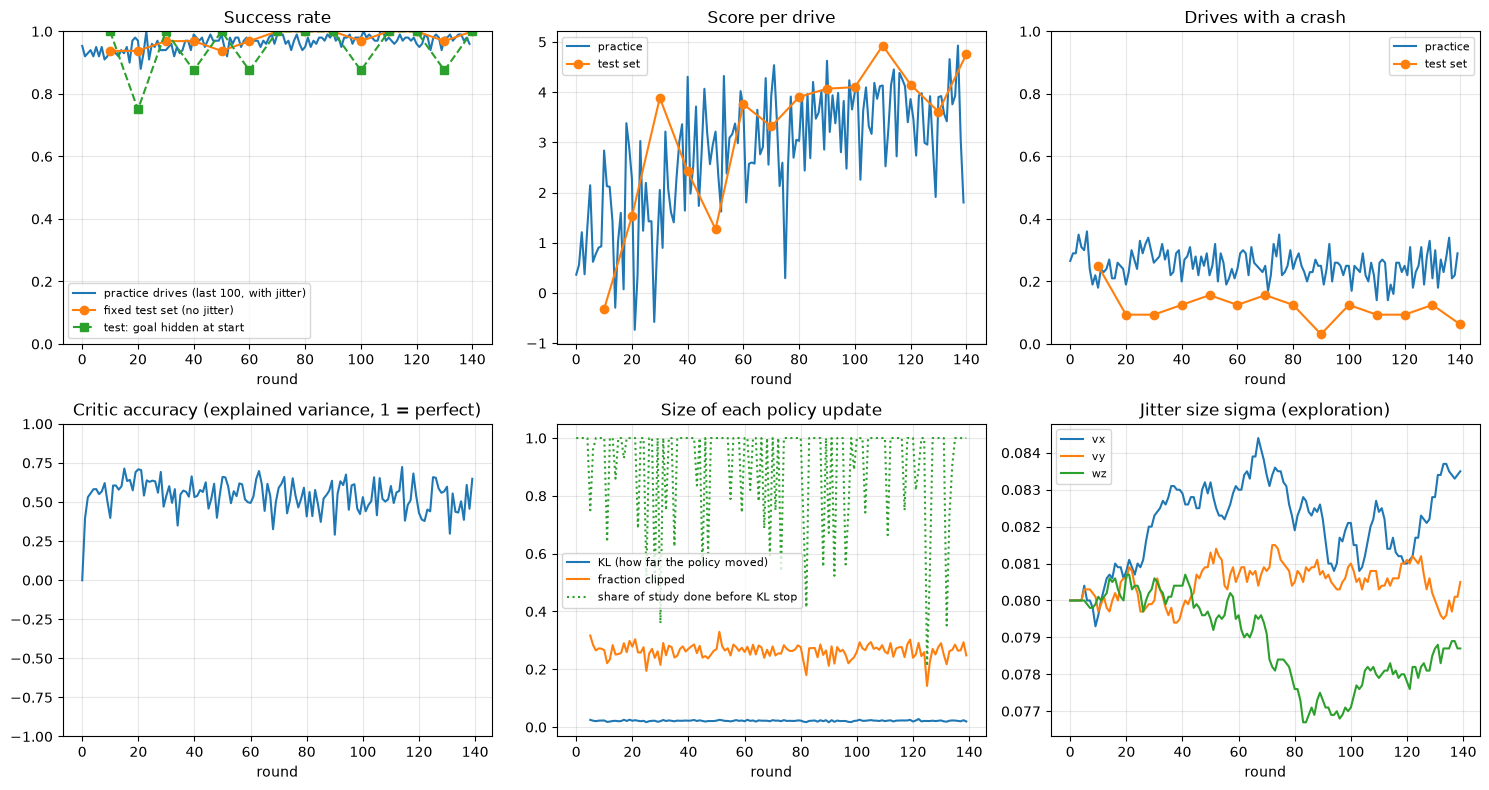

finished run: 140 rounds; quick tests at rounds [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140]


In [4]:
FORCE = False
MAX_ROUNDS, MIN_ROUNDS, PATIENCE = 200, 100, 30


class History:
    # a finished run's log, shaped like a trainer for plot_progress
    def __init__(self, run_dir):
        h = json.load(open(run_dir / "history.json"))
        self.log, self.evals, self.episodes = h["log"], h["evals"], h["episodes"]


def finished(run_dir):
    if not (run_dir / "history.json").exists():
        return False
    log = json.load(open(run_dir / "history.json"))["log"]
    std = [e for e in json.load(open(run_dir / "history.json"))["evals"] if e.get("tag", "standard") == "standard"]
    best = max(std, key=lambda e: e["return"])["round"] if std else 0
    n = len(log)
    return n >= MAX_ROUNDS or (n >= MIN_ROUNDS and n - best >= PATIENCE)


if finished(RUN_DIR) and not FORCE:
    H = History(RUN_DIR)
    plot_progress(H); plt.show()
    print(f"finished run: {len(H.log)} rounds; quick tests at rounds {[e['round'] for e in H.evals]}")
else:
    tr = RoutePPOTrainer(cfg, START_CHECKPOINT, RUN_DIR, PREP)
    if (RUN_DIR / "latest.pt").exists():
        tr.load(RUN_DIR / "latest.pt"); print("continuing from round", tr.round)
    fig = plt.figure(figsize=(15, 8))
    try:
        while tr.round < MAX_ROUNDS:
            e = tr.train_round()
            plot_progress(tr, fig); clear_output(wait=True); display(fig)
            ev = f" | TEST success {tr.evals[-1]['success']:.0%} (round {tr.evals[-1]['round']})" if tr.evals else ""
            print(f"round {e['round']:4d}  practice success {e['success_last100'] or 0:.0%}  crash {e['crash_episodes_last100'] or 0:.0%}  "
                  f"critic {e['explained_variance']:+.2f}  KL {e['kl'] if e['kl'] is not None else float('nan'):.3f}  "
                  f"sigma {e['sigma']}  ({e['collect_s']:.0f}+{e['learn_s']:.0f}s){ev}")
            if tr.round % cfg.eval_every == 0 and tr.round >= MIN_ROUNDS:
                std = [x for x in tr.evals if x.get("tag", "standard") == "standard"]
                best = max(std, key=lambda x: x["return"])["round"]
                if tr.round - best >= PATIENCE:
                    print(f"stopping: no new best quick test since round {best}"); break
    except KeyboardInterrupt:
        print("Stopped by you.")
    finally:
        tr.save("latest"); print("saved:", RUN_DIR / "latest.pt")
    plt.close(fig); tr.close()

### 6.1 Is the training healthy? Losses and update sizes

The graphs above show *results* (success, score, crashes). The ones below show the *training itself*: is it learning
safely, or drifting, forgetting or stalling?

**Where is the "validation loss"?** In imitation training (notebooks 04 and 06) we watched the loss on validation
drives to catch overfitting. RL has no single loss like that: the robot practises on fresh random rooms every round, so
it can't memorise rooms. Its real "validation" is the **quick test** (fixed rooms, no jitter) in the graphs above. Two
other things can still go wrong, and we measure both:
* **Forgetting the demos.** Practice could pull the driving away from what the demos taught. Every 10 rounds we measure
  the **demo loss on the validation drives** (the same frames and the same noise each time). A rising red line means
  the car is forgetting how to drive like the demos on drives it never trained on.
* **Updates that are too big or too small.** That's what KL measures (below).

| Graph | What it shows | Healthy | Warning sign |
|---|---|---|---|
| **PPO policy loss** | the clipped "make good actions more likely" objective | jumps around 0 | not useful as a progress meter: its size depends on the advantages, which are re-centred every round |
| **Critic loss and accuracy** | how well the critic predicts the score from here on | loss settling, explained variance 0.2–0.8 | accuracy near 0 or negative: the advantages are noise |
| **Demo loss: train vs validation** | the "practise the demos" lesson | validation stays near its round-0 value | validation rising steadily: forgetting |
| **KL** | how far each update moved the policy | below the 0.05 guard most rounds | at the guard every round, or near 0 for many rounds |
| **Clipping, study done** | how much of each round's planned learning happened | clipped < ~0.3, study done mostly 1.0 | study done very low every round: the guard cuts almost all learning |
| **Demo lesson weight** | fades from 1.0 to 0.1 over 100 rounds | — | — |

**Is KL relevant here? Yes, it's one of the most important health numbers for PPO.** KL (Kullback–Leibler
divergence) measures how different the policy is *after* a round's update from the policy that *collected* that round's
drives. PPO's learning signal is only trustworthy for small changes: it judges new actions using drives that the old
policy collected. A big change makes that judgement unreliable, and the robot can get suddenly worse. So:
* **Too high** (at or above the 0.05 guard, red line): the update went too far. Our guard then stops that round's
  learning early (red crosses). Occasional crosses are fine; crosses every round mean the learning rate is too high
  for this model. Notebook 05 measured a KL of 1.4 at a normal fine-tuning learning rate, which is why the rate is
  1e-6.
* **Too low** (near 0 for many rounds): the policy has stopped changing; practice is doing nothing.
* What KL is **not**: it is measured round by round, so it doesn't show how far the car has drifted from where it
  *started*. That drift is what the validation demo loss shows.

**Why some red crosses sit well below the red line.** The KL plotted is the *average over the whole round*. The guard
watches the *last 4 mini-batches* and stops the round as soon as *they* average above 0.05. So a round can be stopped
by a late spike while its average stays at 0.02. Occasional early stops are normal; the "share of study done" line
shows how much of that round's learning still happened (usually most of it).

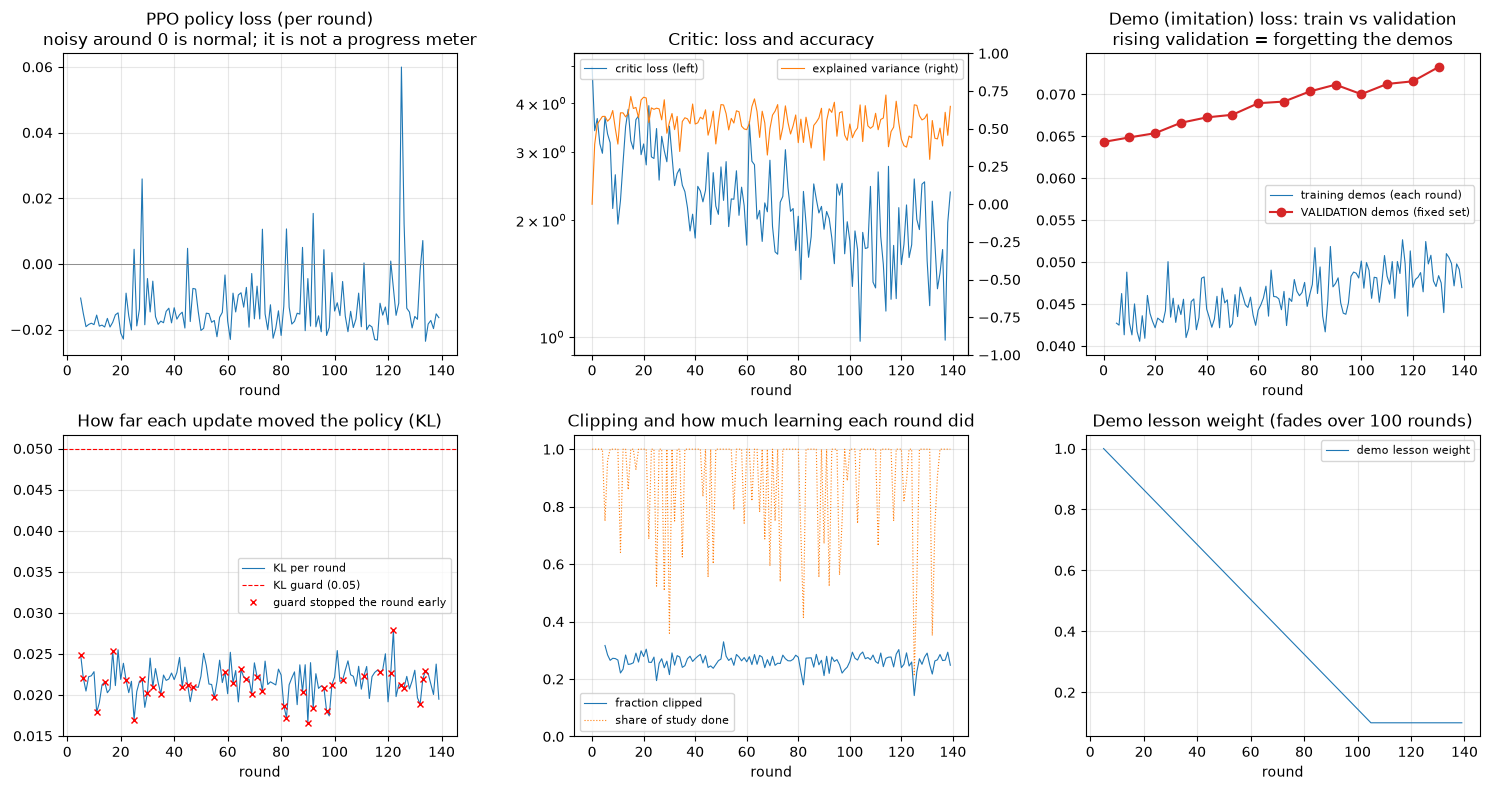

In [5]:
plot_health(H if "H" in globals() else tr); plt.show()

**The run in numbers.** Practice drives averaged over 10-round blocks, and every quick test (32 rooms, no jitter).

In [6]:
H = History(RUN_DIR)
blocks = []
for b in range(0, len(H.log), 10):
    L = H.log[b:b + 10]
    m = lambda k: np.nanmean([x[k] for x in L if x.get(k) is not None]) if any(x.get(k) is not None for x in L) else np.nan
    blocks.append({"rounds": f"{b}-{b + len(L) - 1}", "practice success": m("success_last100"), "drives with a crash": m("crash_episodes_last100"),
                   "score per drive": m("return_last100"), "critic": m("explained_variance"), "KL": m("kl"), "demo loss": m("bc_loss"),
                   "VALIDATION demo loss": m("val_demo_loss")})
import pandas as pd
display(pd.DataFrame(blocks).set_index("rounds").style.format("{:.3f}"))
display(pd.DataFrame([{k: e[k] for k in ("round", "success", "success_hidden_start", "crash_episodes", "return")} for e in H.evals
                      if e.get("tag", "standard") == "standard"]).set_index("round").style.format("{:.2f}"))

,practice success,drives with a crash,score per drive,critic,KL,demo loss,VALIDATION demo loss
rounds,,,,,,,
0-9,0.931,0.282,0.919,0.489,0.022,0.044,0.064
10-19,0.940,0.233,1.720,0.604,0.022,0.043,0.065
20-29,0.945,0.281,1.147,0.621,0.021,0.044,0.065
30-39,0.947,0.274,2.157,0.545,0.022,0.044,0.067
40-49,0.974,0.262,2.983,0.537,0.022,0.044,0.067
50-59,0.966,0.239,3.050,0.576,0.022,0.045,0.068
60-69,0.969,0.263,2.939,0.541,0.022,0.046,0.069
70-79,0.970,0.259,2.911,0.558,0.022,0.046,0.069
80-89,0.971,0.246,3.420,0.509,0.021,0.047,0.070


,success,success_hidden_start,crash_episodes,return
round,,,,
10,0.94,1.00,0.25,-0.32
20,0.94,0.75,0.09,1.53
30,0.97,1.00,0.09,3.89
40,0.97,0.88,0.12,2.42
50,0.94,1.00,0.16,1.27
60,0.97,0.88,0.12,3.76
70,1.00,1.00,0.16,3.32
80,1.00,1.00,0.12,3.90
90,1.00,1.00,0.03,4.07


## 7. The full tests: before and after practice

The same 128 rooms and the same three test modes as notebook 06 (help on, help switched off, help from the wrong
room), with the server running live on every decision. `best.pt` (the best quick test) is loaded on top of the
starting car. About 35 minutes.

already done: runs/car06_tests/car07_route_ppo_s0.json


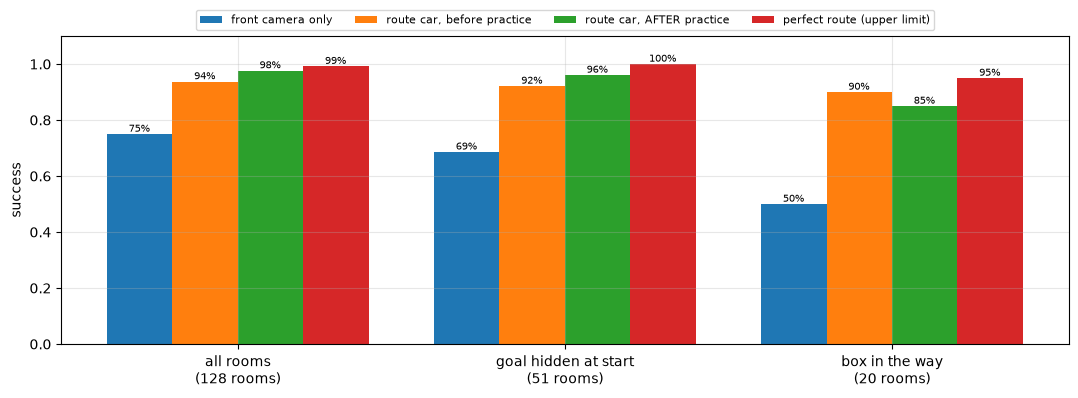

,success,goal hidden at start,box in the way,touched something,s per success,"s per success, hidden",failures,...stuck
car,,,,,,,,
front camera only,75%,69%,50%,52%,14.3,23.1,32,25
"route car, before practice",94%,92%,90%,22%,8.0,11.0,8,7
"route car, AFTER practice",98%,96%,85%,19%,8.5,12.2,3,3
perfect route (upper limit),99%,100%,95%,4%,6.8,8.8,1,1
after practice: help OFF,76%,59%,40%,58%,15.0,21.2,31,27
after practice: WRONG-room help,60%,59%,35%,83%,20.7,24.9,51,49


In [3]:
CK = RUNS / "checkpoints"
nb06.run(["scripts/car06_tests.py", "--car", START_CHECKPOINT, "--ppo", RUN_DIR / "best.pt", "--map", CK / "server_map_long_s0.pt",
          "--out", "runs/car06_tests/car07_route_ppo_s0.json"], ["runs/car06_tests/car07_route_ppo_s0.json"], force=False)
ROWS = [("front camera only", "F_s0", "help"), ("route car, before practice", "car06_R_long_s0", "help"),
        ("route car, AFTER practice", "car07_route_ppo_s0", "help"), ("perfect route (upper limit)", "car06_Rstar_s0", "help")]
nb06.results_chart(ROWS); plt.show()
display(nb06.summary(ROWS + [("after practice: help OFF", "car07_route_ppo_s0", "no_help"),
                             ("after practice: WRONG-room help", "car07_route_ppo_s0", "other_room")]))

### 7.1 Luck tests and where the changes happened

Same rooms, drive by drive (wins : losses), as in notebook 06. Then the rooms split by how much detour they need: if
practice taught backing off, the gains should be in the most-detour third.

In [8]:
display(nb06.paired_table([
    ("after vs before practice", ("car07_route_ppo_s0", "help"), ("car06_R_long_s0", "help")),
    ("after practice vs front camera only", ("car07_route_ppo_s0", "help"), ("F_s0", "help")),
    ("after practice vs perfect route", ("car07_route_ppo_s0", "help"), ("car06_Rstar_s0", "help")),
    ("after practice: help on vs off", ("car07_route_ppo_s0", "help"), ("car07_route_ppo_s0", "no_help")),
]))
display(nb06.detour_thirds(ROWS))

,all rooms,goal hidden,box in the way
comparison,,,
after vs before practice,7:2 p = 0.180 (could be luck),3:1 p = 0.625 (could be luck),1:2 p = 1.000 (could be luck)
after practice vs front camera only,29:0 p = 0.000 (real),14:0 p = 0.000 (real),7:0 p = 0.016 (real)
after practice vs perfect route,1:3 p = 0.625 (could be luck),0:2 p = 0.500 (could be luck),1:3 p = 0.625 (could be luck)
after practice: help on vs off,29:1 p = 0.000 (real),19:0 p = 0.000 (real),10:1 p = 0.012 (real)


,least detour,middle,most detour
car,,,
front camera only,84% (5 stuck),76% (8 stuck),65% (12 stuck)
"route car, before practice",100% (0 stuck),93% (2 stuck),88% (5 stuck)
"route car, AFTER practice",100% (0 stuck),100% (0 stuck),93% (3 stuck)
perfect route (upper limit),100% (0 stuck),100% (0 stuck),98% (1 stuck)


### 7.2 Watch it drive

The route car after practice (`best.pt`, loaded on top of notebook 06's route car) drives one room in Genesis, with the server running live as in the tests. Loading takes about a minute; the drive itself is quick.

The video shows two views side by side. **Left:** the overhead camera (the server's view; the car only gets the route from it). Blue = where the car has driven; orange = the server's planned route and its estimate of where the goal is, renewed every half second.
**Right:** the car's front camera, the only picture its own model sees. The text on top shows the time and whether the
car is touching something. The video plays at 2× speed.

**Settings:** `ROOM` = any layout seed (try others: every seed is a different room); `LIVE = True` also opens the
Genesis 3-D window with a chase camera and drives at real-time speed (needs a screen; the window closes when the drive
ends); `FORCE = True` drives again instead of reusing the saved video (in `runs/videos/`).

**One drive is an example, not a test.** The default room was picked to show the difference between the notebooks'
cars (it comes from the standard test, and the front-camera cars of notebooks 04 and 05 fail it). The success rates are
the tests above. A single drive can also differ from the same room in the test: the test words the instruction
differently (e.g. "move to" vs "head over to"), and small changes add up over a minute of driving.

**What you should see:** In the default room the goal is hidden behind a long wall at the start. Before practice (notebook 06) the route car got there in about 32 s, 20 of them pinned on an obstacle. After practice it backs off and gets there in about 20 s, with about 5 s of touching.

In [ ]:
from carsim.viz import watch_drive
ROOM, LIVE, FORCE = 623600484, False, False
watch_drive(START_CHECKPOINT, RUN_DIR / "best.pt", room=ROOM, name="nb07_route_ppo_car", title="notebook 07: route help + PPO",
            live=LIVE, force=FORCE)

{"room": 623600484, "prompt": "move to the blue cylinder", "success": true, "seconds": 20.2, "seconds_touching": 4.8, "video": "/home/mayur/Projects/obstacle_avoidance/runs/videos/nb07_route_ppo_car_room623600484.mp4"} (9 s to run)


## 8. What we found

The numbers are from the project's own run (seed 0). RL runs are less repeatable than imitation (the order in which
the 8 simulators finish drives changes what is practised), so a rerun lands close to these numbers, not exactly on them.

**The run.** Practice stopped at **round 140**: the best quick test was round 110 (32 of 32 successes, 9% of drives
touching something), and no later quick test beat it within 30 rounds. `best.pt` = round 110. Training stayed
healthy throughout: KL about 0.02 (never at the guard for long), exploration noise steady at about 0.08, critic
accuracy 0.4–0.65. **One thing to watch:** the validation demo loss rose steadily the whole run, from 0.064 to 0.073
(+14%), and so did the training demo loss (0.042 → 0.049). The car is slowly drifting away from how the demos drive.
Its test results improved at the same time, so the drift is the car finding its own (better) way out of tight spots,
not forgetting how to drive. But in a longer run it is the first thing to check: a validation line that keeps rising
*while the quick tests fall* would mean stop.

**Full tests, the same 128 rooms as notebook 06:**

| | route car before practice | **after practice** | perfect route | front camera only |
|---|---|---|---|---|
| success | 94% | **98%** | 99% | 75% |
| ... goal hidden at start | 92% | **96%** | 100% | 69% |
| ... box in the way (20 rooms) | 90% | 85% | 95% | 50% |
| failed drives (stuck) | 8 (7) | **3 (3)** | 1 (1) | 32 (25) |
| drives that touched something | 22% | 19% | 4% | 52% |
| seconds touching per drive | 3.0 | **1.6** | | |
| seconds per success | 8.0 | 8.5 | 6.8 | 14.3 |
| with help switched OFF | 67% | **76%** | 58% | — |

**1. Practice made a good car better, but on 128 rooms the gain is not yet beyond luck.** Success 94% → 98% and
failures 8 → 3: room by room, 7 rooms won and 2 lost (p = 0.18). Touching time halved (3.0 → 1.6 s per drive),
but by room that is 23 rooms better and 14 worse (p = 0.10). Everything points the same way, but with only 8 failures
left to fix, 128 rooms can't prove it. More test rooms (512) or a second seed would.

**2. It closed the gap to the perfect route.** After practice the real-route car and the perfect-route car are within
luck of each other (1 room won, 3 lost, p = 0.63). The car that started at 75% with its front camera alone now
succeeds in 98% of rooms using a real ceiling camera, a real server and 36 bytes every half second (29 rooms won, 0
lost against the front-camera car).

**3. Where it helped.** The middle third of rooms by detour went from 93% to 100%, and the most-detour third from
88% to 93%. In the 20 box-in-the-way rooms it is level (90% → 85%, 1 room won, 2 lost: luck). The 3 failures left
are all cars pinned on something for 10–54 s, in rooms with a long detour (route 1.5–4.8 times the straight line).

**4. A surprise: the car got better *without* help too** (67% → 76%; 25 rooms won, 14 lost, p = 0.11). Practising
backing off obstacles is a skill it keeps when the route is gone. Note that practice always had the route switched
on, so this was never practised directly.

**5. It still reads the route:** help on vs off, 29 rooms won and 1 lost; with the wrong room's route it drops to 60%.

**Compared with notebook 05.** There, practice cured the bumping, but success didn't rise: the freed car then lost
the goal and had no way to find it again. Here the route provides that, so the same practice turns into successes.
Practice and route help do different jobs: practice teaches *how to get unstuck*, the route says *where to go*. Each
alone left the car short; together they nearly reach the perfect route.

## 9. Summary and ideas to try next

**What we built:** the real server inside notebook 05's practice loop, made affordable by planning once per drive and
tracking the car every half second; the same reward, settings and "practise the demos" lesson; a stopping rule for a
run that starts near the top.

**Ideas to try next**
* **A second seed and more test rooms** (512 instead of 128): the differences left between the cars are a few points,
  below what 128 rooms can prove.
* **Network delay:** send the route a little late during practice and testing. Practice could teach the car to cope with
  a slightly stale route.
* **Ask only when needed:** with practice, the car might need the route less often. A small "asker" trained over the
  frozen driver (Ask4Help, arXiv 2211.09960) could request help only when the drive looks risky, at a cost per request.
* **Practice on harder rooms:** more boxes in the way, narrower gaps (`practice_layout` in `PPOConfig`).